In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
import os

path = "."

for folder in os.listdir(path):
    if os.path.isdir(folder):
        print(folder, ":", len(os.listdir(folder)), "items")

.ipynb_checkpoints : 1 items
Bacterial leaf blight-20200814T055237Z-001 : 1 items
Brown spot-20200814T055208Z-001 : 1 items
Leaf smut-20200814T055530Z-001 : 1 items


In [5]:
import os

path = os.getcwd()

total = 0

for folder in os.listdir(path):
    folder_path = os.path.join(path, folder)

    if os.path.isdir(folder_path):
        count = 0

        for root, dirs, files in os.walk(folder_path):
            count += sum(
                f.lower().endswith(('.jpg', '.jpeg', '.png'))
                for f in files
            )

        if count > 0:
            print(folder, ":", count, "images")
            total += count

print("Total Images:", total)

Bacterial leaf blight-20200814T055237Z-001 : 40 images
Brown spot-20200814T055208Z-001 : 40 images
Leaf smut-20200814T055530Z-001 : 39 images
Total Images: 119


In [7]:
import os

print(os.getcwd())
print(os.listdir())

C:\Users\Admin\Desktop\RiceLeaf_project\PRCP-1001-RiceLeaf\Data
['.ipynb_checkpoints', 'Bacterial leaf blight-20200814T055237Z-001', 'Bacterial leaf blight-20200814T055237Z-001.zip', 'Brown spot-20200814T055208Z-001', 'Brown spot-20200814T055208Z-001.zip', 'Leaf smut-20200814T055530Z-001', 'Leaf smut-20200814T055530Z-001.zip', 'rice_life_disease_detection.ipynb']


In [8]:
import os

for root, dirs, files in os.walk(os.getcwd()):
    print(root, "Images:", len([
        f for f in files
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]))

C:\Users\Admin\Desktop\RiceLeaf_project\PRCP-1001-RiceLeaf\Data Images: 0
C:\Users\Admin\Desktop\RiceLeaf_project\PRCP-1001-RiceLeaf\Data\.ipynb_checkpoints Images: 0
C:\Users\Admin\Desktop\RiceLeaf_project\PRCP-1001-RiceLeaf\Data\Bacterial leaf blight-20200814T055237Z-001 Images: 0
C:\Users\Admin\Desktop\RiceLeaf_project\PRCP-1001-RiceLeaf\Data\Bacterial leaf blight-20200814T055237Z-001\Bacterial leaf blight Images: 40
C:\Users\Admin\Desktop\RiceLeaf_project\PRCP-1001-RiceLeaf\Data\Brown spot-20200814T055208Z-001 Images: 0
C:\Users\Admin\Desktop\RiceLeaf_project\PRCP-1001-RiceLeaf\Data\Brown spot-20200814T055208Z-001\Brown spot Images: 40
C:\Users\Admin\Desktop\RiceLeaf_project\PRCP-1001-RiceLeaf\Data\Leaf smut-20200814T055530Z-001 Images: 0
C:\Users\Admin\Desktop\RiceLeaf_project\PRCP-1001-RiceLeaf\Data\Leaf smut-20200814T055530Z-001\Leaf smut Images: 39


In [10]:
import os

for folder in os.listdir():
    print(folder)

.ipynb_checkpoints
Bacterial leaf blight-20200814T055237Z-001
Bacterial leaf blight-20200814T055237Z-001.zip
Brown spot-20200814T055208Z-001
Brown spot-20200814T055208Z-001.zip
Leaf smut-20200814T055530Z-001
Leaf smut-20200814T055530Z-001.zip
rice_life_disease_detection.ipynb


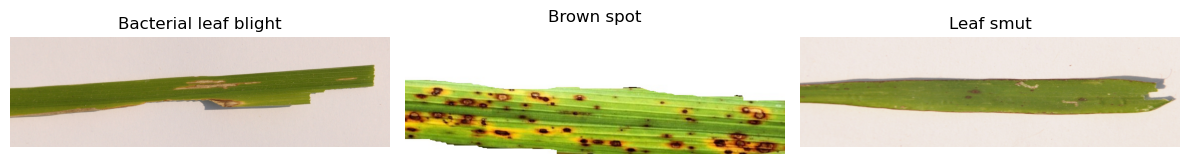

In [11]:
import os
import matplotlib.pyplot as plt
from PIL import Image

classes = ["Bacterial leaf blight", "Brown spot", "Leaf smut"]

plt.figure(figsize=(12, 5))

for i, disease in enumerate(classes):
    folder = next(
        f for f in os.listdir()
        if f.startswith(disease) and os.path.isdir(f)
    )

    images = []
    for root, dirs, files in os.walk(folder):
        for f in files:
            if f.lower().endswith(('.jpg', '.jpeg', '.png')):
                images.append(os.path.join(root, f))

    img = Image.open(images[0])

    plt.subplot(1, 3, i+1)
    plt.imshow(img)
    plt.title(disease)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
import os

classes = ["Bacterial leaf blight", "Brown spot", "Leaf smut"]

counts = []

for disease in classes:
    folder = next(f for f in os.listdir()
                  if f.startswith(disease) and os.path.isdir(f))

    count = 0

    for root, dirs, files in os.walk(folder):
        count += sum(f.lower().endswith(('.jpg', '.jpeg', '.png'))
                     for f in files)

    counts.append(count)
    print(disease, ":", count)

print("Total Images:", sum(counts))

Bacterial leaf blight : 40
Brown spot : 40
Leaf smut : 39
Total Images: 119


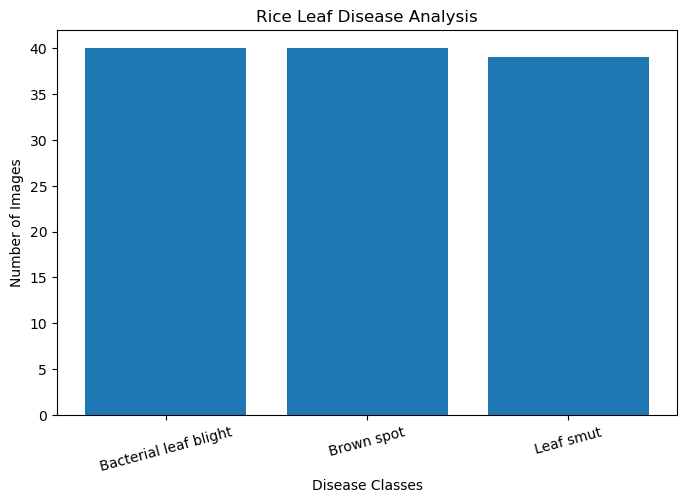

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.bar(classes, counts)

plt.title("Rice Leaf Disease Analysis")
plt.xlabel("Disease Classes")
plt.ylabel("Number of Images")

plt.xticks(rotation=15)
plt.show()

In [15]:
import os
import numpy as np
from PIL import Image

classes = ["Bacterial leaf blight", "Brown spot", "Leaf smut"]

images = []
labels = []

for i, disease in enumerate(classes):

    folder = next(f for f in os.listdir()
                  if f.startswith(disease) and os.path.isdir(f))

    for root, dirs, files in os.walk(folder):
        for file in files:

            if file.lower().endswith(('.jpg', '.jpeg', '.png')):
                path = os.path.join(root, file)

                try:
                    img = Image.open(path).convert("RGB")
                    img = img.resize((128, 128))

                    images.append(np.array(img) / 255.0)
                    labels.append(i)

                except Exception:
                    print("Skipped:", path)

X = np.array(images, dtype=np.float32)
y = np.array(labels)

print("Image Shape:", X.shape)
print("Label Shape:", y.shape)
print("Preprocessing Completed!")

Image Shape: (119, 128, 128, 3)
Label Shape: (119,)
Preprocessing Completed!


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Images:", len(X_train))
print("Testing Images:", len(X_test))
print("Train Test Split Completed!")

Training Images: 95
Testing Images: 24
Train Test Split Completed!


In [18]:
!pip install tensorflow

In [23]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [21]:
import tensorflow as tf

print("TensorFlow Working!")
print(tf.__version__)

TensorFlow Working!
2.21.0


In [22]:
print("python")

python


In [24]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout

model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(128,128,3)),
    MaxPooling2D(2,2),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(3, activation='softmax')
])

model.summary()

C:\Users\Admin\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 57600)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       7,372,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 7,392,707 (28.20 MB)

 Trainable params: 7,392,707 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

In [26]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [27]:
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=16,
    validation_data=(X_test, y_test)
)

Epoch 1/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 379ms/step - accuracy: 0.2947 - loss: 2.5654 - val_accuracy: 0.3333 - val_loss: 1.1541
Epoch 2/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 388ms/step - accuracy: 0.3895 - loss: 1.1180 - val_accuracy: 0.4583 - val_loss: 1.0823
Epoch 3/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 276ms/step - accuracy: 0.4316 - loss: 1.0856 - val_accuracy: 0.3333 - val_loss: 1.0777
Epoch 4/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 271ms/step - accuracy: 0.4632 - loss: 1.0258 - val_accuracy: 0.5000 - val_loss: 1.0262
Epoch 5/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 270ms/step - accuracy: 0.5368 - loss: 0.9479 - val_accuracy: 0.5833 - val_loss: 0.9419
Epoch 6/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 270ms/step - accuracy: 0.6105 - loss: 0.9192 - val_accuracy: 0.6667 - val_loss: 0.8130
Epoch 7/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 281ms/step - accuracy: 0.7263 - loss: 0.6893 - val_accuracy: 0.5833 - val_loss: 0.8669
Epoch 8/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 275ms/step - accuracy: 0.7895 - loss: 0.5783 - val_accuracy: 0.7500 - val_loss:

In [28]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", test_accuracy * 100, "%")
print("Test Loss:", test_loss)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - accuracy: 0.7917 - loss: 0.7070
Test Accuracy: 79.16666865348816 %
Test Loss: 0.7070193886756897


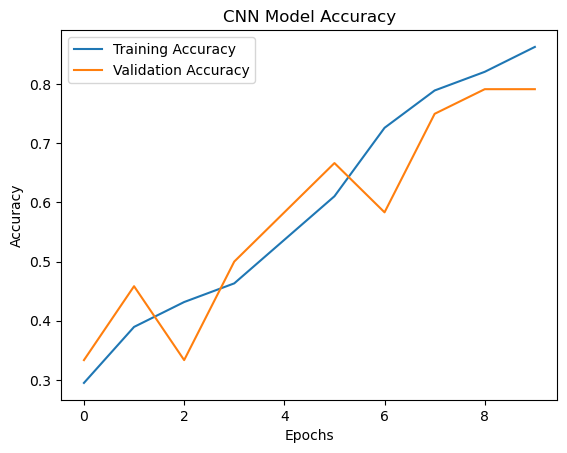

In [29]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('CNN Model Accuracy')
plt.legend()
plt.show()

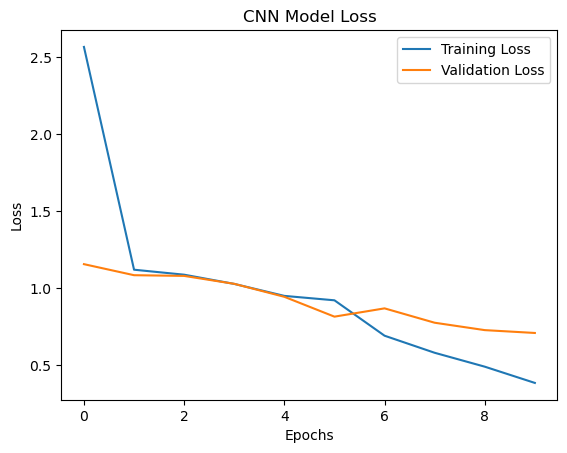

In [30]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('CNN Model Loss')
plt.legend()
plt.show()

In [31]:
model.save("rice_leaf_disease_model.keras")
print("Model Saved Successfully!")

Model Saved Successfully!


In [32]:
from PIL import Image
import numpy as np

img_path = "test_leaf.jpg"  # Your image file name

img = Image.open(img_path).convert("RGB")
img = img.resize((128, 128))

img_array = np.array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)
result = classes[np.argmax(prediction)]

print("Predicted Disease:", result)

FileNotFoundError: [Errno 2] No such file or directory: 'test_leaf.jpg'

In [33]:
import os

for root, dirs, files in os.walk("."):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            print(os.path.join(root, file))
            break

.\Bacterial leaf blight-20200814T055237Z-001\Bacterial leaf blight\DSC_0365.JPG
.\Brown spot-20200814T055208Z-001\Brown spot\DSC_0100.jpg
.\Leaf smut-20200814T055530Z-001\Leaf smut\DSC_0293.JPG


In [34]:
img_path = r".\Bacterial leaf blight-20200814T055237Z-001\Bacterial leaf blight\DSC_0365.JPG"

img = Image.open(img_path).convert("RGB")
img = img.resize((128, 128))

img_array = np.array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)
result = classes[np.argmax(prediction)]

print("Predicted Disease:", result)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Predicted Disease: Bacterial leaf blight


In [35]:
test_images = [
    r".\Bacterial leaf blight-20200814T055237Z-001\Bacterial leaf blight\DSC_0365.JPG",
    r".\Brown spot-20200814T055208Z-001\Brown spot\DSC_0100.jpg",
    r".\Leaf smut-20200814T055530Z-001\Leaf smut\DSC_0293.JPG"
]

for path in test_images:
    img = Image.open(path).convert("RGB")
    img = img.resize((128, 128))

    arr = np.array(img) / 255.0
    arr = np.expand_dims(arr, axis=0)

    pred = model.predict(arr, verbose=0)
    print("Image:", os.path.basename(path))
    print("Predicted Disease:", classes[np.argmax(pred)])
    print("----------------------")

Image: DSC_0365.JPG
Predicted Disease: Bacterial leaf blight
----------------------
Image: DSC_0100.jpg
Predicted Disease: Brown spot
----------------------
Image: DSC_0293.JPG
Predicted Disease: Leaf smut
----------------------


In [36]:
import pandas as pd

results = []

for path in test_images:
    img = Image.open(path).convert("RGB")
    img = img.resize((128, 128))

    arr = np.array(img) / 255.0
    arr = np.expand_dims(arr, axis=0)

    pred = model.predict(arr, verbose=0)
    disease = classes[np.argmax(pred)]

    results.append({
        "Image": os.path.basename(path),
        "Predicted Disease": disease
    })

df = pd.DataFrame(results)
df.to_csv("Rice_Leaf_Predictions.csv", index=False)

print(df)
print("Results Saved Successfully!")

          Image      Predicted Disease
0  DSC_0365.JPG  Bacterial leaf blight
1  DSC_0100.jpg             Brown spot
2  DSC_0293.JPG              Leaf smut
Results Saved Successfully!


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 262ms/step


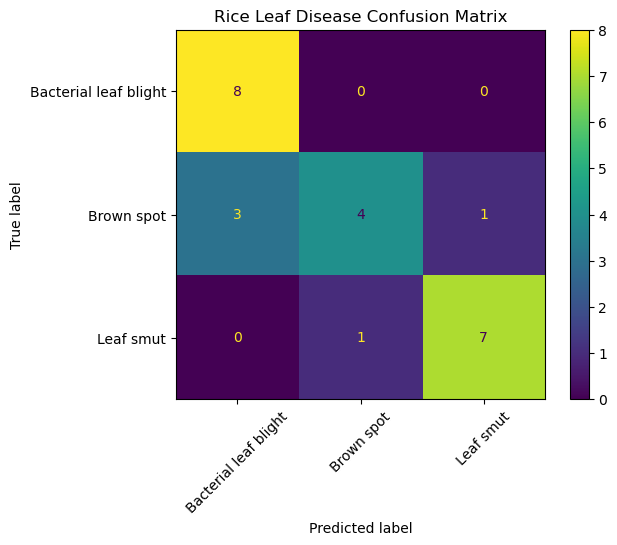

In [37]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = np.argmax(model.predict(X_test), axis=1)

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(xticks_rotation=45)
plt.title("Rice Leaf Disease Confusion Matrix")
plt.show()

In [38]:
from sklearn.metrics import classification_report

y_pred = np.argmax(model.predict(X_test), axis=1)

print(classification_report(
    y_test,
    y_pred,
    target_names=classes
))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
                       precision    recall  f1-score   support

Bacterial leaf blight       0.73      1.00      0.84         8
           Brown spot       0.80      0.50      0.62         8
            Leaf smut       0.88      0.88      0.88         8

             accuracy                           0.79        24
            macro avg       0.80      0.79      0.78        24
         weighted avg       0.80      0.79      0.78        24



In [39]:
model.save("Rice_Leaf_Disease_CNN.keras")

print("CNN Model Saved Successfully!")

CNN Model Saved Successfully!


In [40]:
%%writefile app.py

import streamlit as st
import tensorflow as tf
import numpy as np
from PIL import Image

model = tf.keras.models.load_model("Rice_Leaf_Disease_CNN.keras")

classes = ["Bacterial leaf blight", "Brown spot", "Leaf smut"]

st.title("Rice Leaf Disease Detection")

file = st.file_uploader("Upload Rice Leaf Image", type=["jpg", "jpeg", "png"])

if file:
    img = Image.open(file).convert("RGB")
    st.image(img)

    img = img.resize((128, 128))
    arr = np.array(img) / 255.0
    arr = np.expand_dims(arr, axis=0)

    pred = model.predict(arr)
    result = classes[np.argmax(pred)]

    st.success("Predicted Disease: " + result)

Writing app.py


In [ ]:
!streamlit run app.py

MODEL COMPARISON REPORT


In [43]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score
import pandas as pd
import numpy as np

# CNN Accuracy
cnn_acc = model.evaluate(X_test, y_test, verbose=0)[1]

# Convert images into features
X_train_flat = X_train.reshape(len(X_train), -1)
X_test_flat = X_test.reshape(len(X_test), -1)

# SVM Model
svm = make_pipeline(StandardScaler(), SVC())
svm.fit(X_train_flat, y_train)
svm_pred = svm.predict(X_test_flat)
svm_acc = accuracy_score(y_test, svm_pred)

# Random Forest Model
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_flat, y_train)
rf_pred = rf.predict(X_test_flat)
rf_acc = accuracy_score(y_test, rf_pred)

# Comparison
comparison = pd.DataFrame({
    "Model": ["CNN", "SVM", "Random Forest"],
    "Accuracy": [cnn_acc, svm_acc, rf_acc]
})

print(comparison)

           Model  Accuracy
0            CNN  0.791667
1            SVM  0.833333
2  Random Forest  0.791667


In [44]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["CNN", "SVM", "Random Forest"],
    "Accuracy (%)": [
        cnn_acc * 100,
        svm_acc * 100,
        rf_acc * 100
    ]
})

print(comparison)

           Model  Accuracy (%)
0            CNN     79.166669
1            SVM     83.333333
2  Random Forest     79.166667


In [45]:
best_model = comparison.loc[
    comparison["Accuracy (%)"].idxmax(), "Model"
]

print("Best Performing Model:", best_model)

Best Performing Model: SVM


In [46]:
challenges = {
    "Challenge": [
        "Dataset folder path mismatch",
        "Different image formats",
        "Different image sizes",
        "Pixel value variation",
        "Limited dataset",
        "TensorFlow installation issue"
    ],
    "Technique Used": [
        "os.walk()",
        "PIL Image",
        "Image Resizing",
        "Normalization",
        "Train-Test Split",
        "Package Installation"
    ],
    "Reason": [
        "To locate dataset folders",
        "To read different image formats",
        "To maintain uniform image size",
        "To scale pixel values between 0 and 1",
        "To evaluate model performance",
        "To run CNN model successfully"
    ]
}

challenge_df = pd.DataFrame(challenges)
print(challenge_df)

                       Challenge        Technique Used  \
0   Dataset folder path mismatch             os.walk()   
1        Different image formats             PIL Image   
2          Different image sizes        Image Resizing   
3          Pixel value variation         Normalization   
4                Limited dataset      Train-Test Split   
5  TensorFlow installation issue  Package Installation   

                                  Reason  
0              To locate dataset folders  
1        To read different image formats  
2         To maintain uniform image size  
3  To scale pixel values between 0 and 1  
4          To evaluate model performance  
5          To run CNN model successfully  


In [47]:
challenge_df.to_csv("Rice_Leaf_Challenges_Report.csv", index=False)
print("Challenges Report Saved Successfully!")

Challenges Report Saved Successfully!


In [50]:
import tensorflow as tf
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

print("Data Augmentation Created Successfully")

Data Augmentation Created Successfully


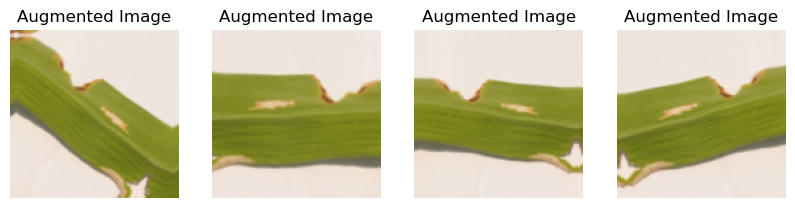

In [51]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

for i in range(4):
    augmented_img = data_augmentation(
        tf.expand_dims(X_train[0], axis=0),
        training=True
    )
    
    plt.subplot(1, 4, i + 1)
    plt.imshow(augmented_img[0].numpy())
    plt.axis("off")
    plt.title("Augmented Image")

plt.show()


In [52]:

aug_model = tf.keras.Sequential([
    data_augmentation,
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(128,128,3)),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(3, activation='softmax')
])

aug_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Augmented CNN Model Created Successfully")


Augmented CNN Model Created Successfully


C:\Users\Admin\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [53]:

history_aug = aug_model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=8,
    validation_data=(X_test, y_test)
)


Epoch 1/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 6s 199ms/step - accuracy: 0.2737 - loss: 3.5249 - val_accuracy: 0.3333 - val_loss: 1.0954
Epoch 2/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 174ms/step - accuracy: 0.3684 - loss: 1.1027 - val_accuracy: 0.3750 - val_loss: 1.0141
Epoch 3/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 176ms/step - accuracy: 0.3684 - loss: 1.0681 - val_accuracy: 0.5417 - val_loss: 0.9668
Epoch 4/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 173ms/step - accuracy: 0.4947 - loss: 1.0192 - val_accuracy: 0.5417 - val_loss: 0.8971
Epoch 5/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 171ms/step - accuracy: 0.4947 - loss: 1.0085 - val_accuracy: 0.6250 - val_loss: 0.8675
Epoch 6/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 174ms/step - accuracy: 0.4842 - loss: 1.0111 - val_accuracy: 0.6250 - val_loss: 0.7779
Epoch 7/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 170ms/step - accuracy: 0.4632 - loss: 1.0017 - val_accuracy: 0.5000 - val_loss: 0.8759
Epoch 8/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 171ms/step - accuracy: 0.4842 - loss: 0.9606 - val_accuracy: 0.

In [54]:

original_loss, original_acc = model.evaluate(X_test, y_test, verbose=0)

aug_loss, aug_acc = aug_model.evaluate(X_test, y_test, verbose=0)

print("Original CNN Accuracy:", original_acc * 100, "%")
print("Augmented CNN Accuracy:", aug_acc * 100, "%")

if aug_acc > original_acc:
    print("Augmented CNN performed better.")
elif original_acc > aug_acc:
    print("Original CNN performed better.")
else:
    print("Both models performed equally.")


Original CNN Accuracy: 79.16666865348816 %
Augmented CNN Accuracy: 54.16666865348816 %
Original CNN performed better.


TASK 3 – DATA AUGMENTATION PERFORMANCE REPORT

Data augmentation techniques such as horizontal flipping, rotation and zooming were applied to the rice leaf training images.

The augmented CNN model was trained and evaluated using the same test dataset as the original CNN model.

The accuracy comparison helps identify the effect of data augmentation on disease classification performance.


In [55]:

import pandas as pd

augmentation_report = pd.DataFrame({
    "Model": ["Original CNN", "Augmented CNN"],
    "Accuracy (%)": [original_acc * 100, aug_acc * 100]
})

print(augmentation_report)


           Model  Accuracy (%)
0   Original CNN     79.166669
1  Augmented CNN     54.166669


In [56]:

aug_model.save("Rice_Leaf_Augmented_CNN.keras")

print("Augmented CNN Model Saved Successfully!")


Augmented CNN Model Saved Successfully!


FINAL PROJECT VERIFICATION

1. Dataset Loading and Preprocessing
2. Exploratory Data Analysis (EDA)
3. Rice Leaf Disease Classification using CNN
4. Data Augmentation
5. Augmented CNN Model Training
6. Original CNN vs Augmented CNN Comparison
7. Model Comparison – CNN, SVM and Random Forest
8. Best Model for Production Report
9. Challenges Faced Report
10. Streamlit Application